<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# Descriptive Statistics

_Author:_ Tim Book, Anonymous

In this notebook we'll implement, review, and interpret various descriptive statistics including the mean, median, mode, variance, standard deviation, range, covariance and correlation.

In [1]:
# Imports...
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Importing the data

In [2]:
df = pd.read_csv('data/top10s_cleaned.csv')
df.head()

,title,artist,top genre,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
0,"Hey, Soul Sister",Train,neo mellow,2010,97,89,67,-4,8,80,217,19,4,83
1,Love The Way You Lie,Eminem,hip hop,2010,87,93,75,-5,52,64,263,24,23,82
2,TiK ToK,Kesha,dance pop,2010,120,84,76,-3,29,71,200,10,14,80
3,Bad Romance,Lady Gaga,dance pop,2010,119,92,70,-4,8,71,295,0,4,79
4,Just the Way You Are,Bruno Mars,pop,2010,109,84,64,-5,9,43,221,2,4,78


## Q: How many observations are there? How many variables?

In [3]:
df.shape

(586, 14)

In [4]:
df.dtypes

title        object
artist       object
top genre    object
year          int64
bpm           int64
nrgy          int64
dnce          int64
dB            int64
live          int64
val           int64
dur           int64
acous         int64
spch          int64
pop           int64
dtype: object

## Q: Which variables are categorical, and which variables are quantitative? 

### Categorical:
* Title
* Artist
* Top genre

### Quantitative:
* Year
* BPM
* nrgy
* dnce
* dB
* live
* val
* dur
* acous
* spch
* pop

# Quantitative Statistics

## Mean

What's the mean danciness of these Top 10 songs?

Compute using `pandas`:

In [5]:
df.dnce.mean()

64.59044368600682

Compute using `numpy`:

In [6]:
np.mean(df.dnce)

64.59044368600682

Finally, "by hand" using other `numpy` functions:

In [7]:
np.sum(df.dnce) / df.shape[0]

64.59044368600682

## Median

In [8]:
df.dnce.median()

66.0

## Skew
Plot the danciness metric. Would you describe this as skew or now? Does the mean vs median disagree?

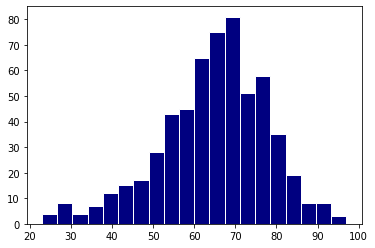

In [17]:
plt.hist(df.dnce, bins=20, color='navy', edgecolor='white');

Do the same mean vs median plotting for acousticity. What do you see?

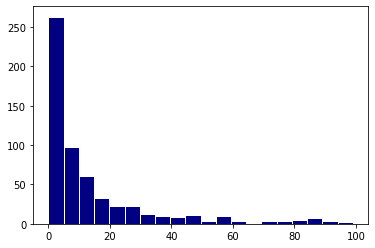

In [21]:
plt.hist(df.acous, bins=20, color='navy', edgecolor='white');

## Variance & Standard Deviation

Let's compute the spread of the energy levels of the music. Let's compute their variances.

First, using `pandas`:

In [24]:
df.nrgy.var()

256.7125463084508

Next, using `numpy`:

In [26]:
# Uh...
np.var(df.nrgy)

256.27447029085954

Finally, "by hand" using other `numpy` functions:

In [27]:
m = np.mean(df.nrgy)
np.sum((df.nrgy - m)**2) / (df.shape[0] - 1)

256.7125463084507

In [28]:
np.sum((df.nrgy - m)**2) / (df.shape[0])

256.27447029085954

Ok, but what about the standard deviation?

In [29]:
df.nrgy.std()

16.022251599211977

In [31]:
np.std(df.nrgy, ddof=1)

16.022251599211977

## Five-number Summary

We can compute all of them pretty quickly with `.describe()`. Let's do that for the _speechiness_ of each song:

In [35]:
df.spch.describe()

count    586.000000
mean       8.290102
std        7.301877
min        3.000000
25%        4.000000
50%        5.000000
75%        9.000000
max       48.000000
Name: spch, dtype: float64

## Boxplot
Does the above summary agree with a boxplot?

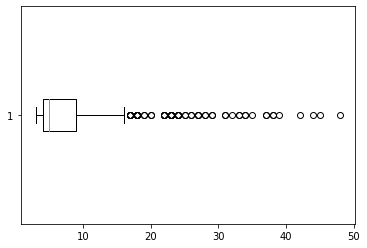

In [40]:
plt.boxplot(df.spch, vert=False);

## Correlation
Let's take a look at the relationship between energy level and volume (dB).

First, let's plot them.

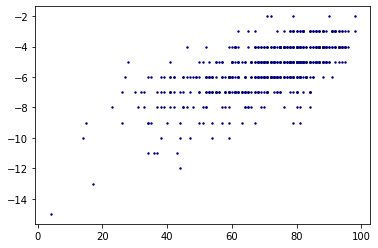

In [44]:
plt.scatter(df.nrgy, df.dB, s=2, c='navy');

We can use `numpy` to compute the correlation coefficient, but it's in a weird format:

In [46]:
np.corrcoef(df.nrgy, df.dB)

array([[1.        , 0.66788421],
       [0.66788421, 1.        ]])

Turns out, statisticians love to look at **correlation matrices**, which is just a big grid of correlations. Notice the diagonal of 1. We can make this easier in `pandas`:

In [41]:
df.corr()

,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
year,1.000000,-0.109518,-0.216868,0.086654,-0.173795,-0.137402,-0.123344,-0.212229,0.097651,0.011397,0.248080
bpm,-0.109518,1.000000,0.101311,-0.184556,0.048342,0.073514,0.002580,-0.027529,-0.128942,0.072840,-0.021826
nrgy,-0.216868,0.101311,1.000000,0.146669,0.667884,0.184692,0.409779,-0.145178,-0.569304,0.117526,-0.086296
dnce,0.086654,-0.184556,0.146669,1.000000,0.137060,-0.029445,0.489765,-0.179351,-0.257697,-0.027290,0.083559
dB,-0.173795,0.048342,0.667884,0.137060,1.000000,0.065603,0.355772,-0.173434,-0.349860,-0.044371,0.024581
live,-0.137402,0.073514,0.184692,-0.029445,0.065603,1.000000,0.026249,0.095488,-0.106835,0.136331,-0.085459
val,-0.123344,0.002580,0.409779,0.489765,0.355772,0.026249,1.000000,-0.266214,-0.256832,0.123224,0.026160
dur,-0.212229,-0.027529,-0.145178,-0.179351,-0.173434,0.095488,-0.266214,1.000000,0.085233,0.034684,-0.101198
acous,0.097651,-0.128942,-0.569304,-0.257697,-0.349860,-0.106835,-0.256832,0.085233,1.000000,-0.019505,0.014825
spch,0.011397,0.072840,0.117526,-0.027290,-0.044371,0.136331,0.123224,0.034684,-0.019505,1.000000,-0.051437


We can also use `seaborn`'s `heatmap()` function to make this a little nicer graphically.

In [47]:
import seaborn as sns

<AxesSubplot:>

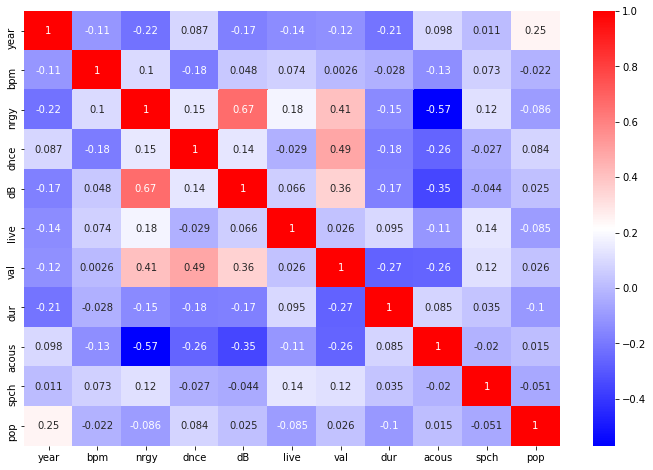

In [53]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), cmap='bwr', annot=True)